## 한글 뉴스 기사의 키워드 분석하기
### 핵심 개념
- 단어: 의미를 갖는 문장의 가장 작은 단일 요소로, 문장에서 분리될 수 있는 부분
- 형태소: 의미가 있는 가장 작은 단위
- 형태소 분석: 다양한 언어학적 속성으로 구조를 파악하는 것
    - 라이브러리 종류 다양함(Hannanum, Kkma, Komoran, Mecab, OKT 등)
    - KoNLPy는 다양한 라이브러리를 파이썬에서 쉽게 사용할 수 있도록 모아둠.
- 품사 태깅(POS, Part-Of Speech): 형태소의 뜻과 문맥을 고려하여 품사를 붙이는 것.
    - 라이브러리마다 그 정도가 다름
### OKT
#### OKT(Open Korean Text)
- 한국어 텍스트를 분석하기 위한 형태소 분석기 중 하나. 비정형적인 한국어 텍스트를 처리하는 데 유용.
#### 주요 기능
- 정규화(normalization): 오타 및 비표준 표현에 의한 분석 오류를 줄이기 위해, 비표준 표현이나 반복 문자를 정리하여 텍스트를 일관된 형태로 변환.
    - ex. 입니닼ㅋㅋㅋㅋㅋ --> 입니다 ㅋㅋ
- 토큰화(tokenization): 텍스트 구조를 파악하기 위해, 문장을 형태소 단위로 분리하고 각 형태소에 품사 정보를 부여.
- 표제어 추출(lemmatization): 단어 빈도 분석 및 검색 효율 향상을 위해, 활용된 용언을 기본형에 가깝게 변환.
- 어구 추출(phase extraction): 주요 개념 및 핵심 구절 추출을 위해, 문장에서 의미 있는 단어 또는 연속된 표현을 추출

In [2]:
from konlpy.tag import Okt

okt = Okt() # 객체로 만듦

text = "한국어를 처리하는 예시입니닼ㅋㅋㅋㅋㅋ"

# 1. 정규화
normalized = okt.normalize(text)
print(normalized)

# 2. 토큰화 및 품사 분석
print(okt.pos(normalized))

# 3. 표제어 추출
print(okt.pos(normalized, stem=True))

# 4. 어구 추출
print(okt.phrases(normalized)) # 명사구 중심

한국어를 처리하는 예시입니다ㅋㅋㅋ
[('한국어', 'Noun'), ('를', 'Josa'), ('처리', 'Noun'), ('하는', 'Verb'), ('예시', 'Noun'), ('입니다', 'Adjective'), ('ㅋㅋㅋ', 'KoreanParticle')]
[('한국어', 'Noun'), ('를', 'Josa'), ('처리', 'Noun'), ('하다', 'Verb'), ('예시', 'Noun'), ('이다', 'Adjective'), ('ㅋㅋㅋ', 'KoreanParticle')]
['한국어', '처리', '처리하는 예시', '예시']


In [2]:
# 0. 라이브러리 임포트

import json
import re
from konlpy.tag import Okt
from collections import Counter
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc
from wordcloud import WordCloud

In [3]:
# 1. 데이터 수집
inputFileName = 'ch08_data/etnews.kr_facebook_2016-01-01_2018-08-01_4차 산업혁명'
data = json.loads(open(inputFileName + '.json', 'r', encoding = 'utf8').read()) # open해서 read한 후, json 타입으로 로드해서 data에 저장. 한글 깨짐 방지 위한 utf-8 인코딩.
print(data)

[{'created_time': '2018-06-20 18:06:39', 'link': 'https://www.facebook.com/etnews.kr/videos/1981346601899735/', 'message': '6월의 스파크포럼 - "미래 시대, 조직의 변화도 시작됐다!"\n\n스파크포럼은 현 사회의 사회문제 및 이슈를 제기하고, 그 이슈를 혁신적으로 해결하고자 하는 소셜이노베이터를 발굴, 지원하여 우리 사회 따뜻한 변화를 확산시키지 위해 만들어진 도전과 만남의 자리입니다.\n\n6월의 스파크포럼에서는 4차 산업혁명 시대의 기업조직과 조직문화를 살펴보고, 조직의 변화를 받아들이고 실험해나가는 사례를 통해 미래 시대 조직이 나아가야 할 방향을 함께 생각해보고자 합니다.', 'name': '6월의 스파크포럼 - "미래 시대, 조직의 변화도 시작됐다!"', 'post_id': '407886705912407_1981346601899735', 'total_comments': 3}, {'created_time': '2018-06-14 10:41:16', 'link': 'http://www.etnews.com/20180612000347', 'message': '로봇이 4차 산업혁명 주요 성장 동력으로 떠오르면서 국내 로봇 기업에 재평가가 이뤄지고 있다는 분석입니다.', 'name': '기술력 갖춘 로봇기업 몸값 치솟는다', 'post_id': '407886705912407_1971252229575839', 'total_comments': 0}, {'created_time': '2018-04-10 17:42:00', 'link': 'http://www.etnews.com/20180409000360?mc=em_002_00001', 'message': '4차 산업혁명 시대 금융 산업 전반 점검해야 한다는...', 'name': "휘청거리는 대한민국 '금융'...서민도 기업도 ICT도 실종", 'post_id': '407886705912407_19007381332939

In [4]:
# 2. 데이터 준비

# 2-1. 데이터 추출
message = ''
for item in data:
    if 'message' in item.keys():
        message = message + re.sub(r'[^\w]', ' ', item['message']) + '' # 유니코드, 숫자, 밑줄 아닌 거 찾아서 공백으로 대체(공백, 탭, 줄바꿈, 특수문자, 구두점, 하이픈 등이 걸림)
print(message)

6월의 스파크포럼    미래 시대  조직의 변화도 시작됐다    스파크포럼은 현 사회의 사회문제 및 이슈를 제기하고  그 이슈를 혁신적으로 해결하고자 하는 소셜이노베이터를 발굴  지원하여 우리 사회 따뜻한 변화를 확산시키지 위해 만들어진 도전과 만남의 자리입니다   6월의 스파크포럼에서는 4차 산업혁명 시대의 기업조직과 조직문화를 살펴보고  조직의 변화를 받아들이고 실험해나가는 사례를 통해 미래 시대 조직이 나아가야 할 방향을 함께 생각해보고자 합니다 로봇이 4차 산업혁명 주요 성장 동력으로 떠오르면서 국내 로봇 기업에 재평가가 이뤄지고 있다는 분석입니다 4차 산업혁명 시대 금융 산업 전반 점검해야 한다는   공통 간판 공약은  4차 산업혁명 선도 도시 구현 과  가상화폐 블록체인 기술 활용  등입니다  https   goo gl qPEyAJ이번 과정은 4차 산업혁명 핵심 기술인 AI에 대한 통찰력과 알파고를 통해 우리 일상과 익숙해진 로봇  빅데이터 산업 흐름을 알려줍니다   인공지능  최고위과정  산학연최고전문가 https   goo gl jSZSNX4차 산업혁명 모든 기술과 서비스 구현산업혁명의 나라  영국엔 4차 산업혁명이 없다  한국 영국 경험과 지혜를 모으는  미래비즈니스포럼 2017  개최 전자신문TV 라이브  SBA 신직업위크  4차 산업혁명 시대의 경쟁력 확보와 일자리 창출의 해법을 신직업에서 찾고 있는 서울산업진흥원 SBA 이 자신들의 역량과 노력을 모두 담은  제 2회 신직업위크 를 진행하고 있습니다   이번 전자신문TV라이브는 서울 대치동 SBA 신직업교육센터에서 강만구 신직업교육팀장과 서지윤 신직업리서치팀수석  윤석원 테스트웍스 대표 등과 함께  제 2회 신직업위크 와 최신 신직업트렌드를 알아보는 시간으로 마련했습니다  많은 시청 바랍니다     전자신문  전자신문엔터  전자신문TV  라이브  소셜방송  현장라이브  손보련  신직업위크  서울산업진흥원  SBA  신직업  서울  강만구  서지윤  윤석원  테스트웍스  소프트웨어  테스터 

In [5]:
# 2-2. 명사 단어 추출

nlp = Okt()
message_N = nlp.nouns(message) # .nouns(): 명사만 뽑음. 중복 체크는 안함.
print(message_N)

['스파크', '포럼', '미래', '시대', '조직', '변화', '시작', '스파크', '포럼', '현', '사회', '사회', '문제', '및', '이슈', '제기', '그', '이슈', '혁신', '해결', '소셜', '이노', '베이', '터', '발굴', '지원', '우리', '사회', '변화', '확산', '위해', '도전', '만남', '자리', '스파크', '포럼', '차', '산업혁명', '시대', '기업', '조직', '직문', '조직', '변화', '실험', '사례', '통해', '미래', '시대', '조직', '방향', '생각', '로봇', '차', '산업혁명', '주요', '성장', '동력', '국내', '로봇', '기업', '재', '평가', '분석', '차', '산업혁명', '시대', '금융', '산업', '전반', '점검', '공통', '간판', '공약', '차', '산업혁명', '선도', '도시', '구현', '과', '가상', '화폐', '블록', '체인', '기술', '활용', '등', '이번', '과정', '차', '산업혁명', '핵심', '기술', '대한', '통찰', '알파', '통해', '우리', '일상', '로봇', '빅데이터', '산업', '흐름', '인공', '지능', '최고', '위', '과정', '산학', '최고', '전문가', '차', '산업혁명', '모든', '기술', '서비스', '산업혁명', '나라', '영국', '차', '산업혁명', '한국', '영국', '경험', '지혜', '미래', '비즈니스', '포럼', '개최', '전자신문', '라이브', '직업', '위', '차', '산업혁명', '시대', '경쟁력', '확보', '일자리', '창', '해법', '직업', '산업', '진흥', '이', '자신', '역량', '노력', '모두', '제', '직업', '위', '를', '진행', '이번', '전자신문', '라이브', '서울', '대치동', '직업', '교육', '센터', '강', '만구', '직

In [7]:
count = Counter(message_N)
print(count)

Counter({'차': 23, '산업혁명': 22, '전자신문': 13, '산업': 10, '직업': 10, '기술': 8, '시대': 7, '라이브': 7, '이번': 6, '진흥': 6, '포럼': 5, '위': 5, '일자리': 5, '창': 5, '조직': 4, '터': 4, '통해': 4, '진행': 4, '스파크': 3, '미래': 3, '변화': 3, '사회': 3, '기업': 3, '로봇': 3, '등': 3, '노력': 3, '서울': 3, '시간': 3, '방송': 3, '대응': 3, '주형': 3, '철': 3, '전자': 3, '정보': 3, '이슈': 2, '소셜': 2, '우리': 2, '위해': 2, '사례': 2, '주요': 2, '국내': 2, '활용': 2, '과정': 2, '빅데이터': 2, '흐름': 2, '최고': 2, '서비스': 2, '영국': 2, '한국': 2, '경쟁력': 2, '제': 2, '를': 2, '교육': 2, '강': 2, '만구': 2, '팀': 2, '지윤': 2, '윤석': 2, '테스트': 2, '웍스': 2, '대표': 2, '시청': 2, '현장': 2, '소프트웨어': 2, '테스': 2, '가장': 2, '과제': 2, '대표이사': 2, '공공기관': 2, '중소기업': 2, '모시': 2, '국정': 2, '컨퍼런스': 2, '행사': 2, '페이스북': 2, '대비': 2, '시작': 1, '현': 1, '문제': 1, '및': 1, '제기': 1, '그': 1, '혁신': 1, '해결': 1, '이노': 1, '베이': 1, '발굴': 1, '지원': 1, '확산': 1, '도전': 1, '만남': 1, '자리': 1, '직문': 1, '실험': 1, '방향': 1, '생각': 1, '성장': 1, '동력': 1, '재': 1, '평가': 1, '분석': 1, '금융': 1, '전반': 1, '점검': 1, '공통': 1, '간판': 1, '공약': 1, '선도': 1, '도시

In [8]:
word_count = dict()
for tag, counts in count.most_common(80): # 출현 횟수 기준 상위 80개 뽑
    if(len(str(tag)) > 1): # 길이가 1보다 큰 것만
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

산업혁명 : 22
전자신문 : 13
산업 : 10
직업 : 10
기술 : 8
시대 : 7
라이브 : 7
이번 : 6
진흥 : 6
포럼 : 5
일자리 : 5
조직 : 4
통해 : 4
진행 : 4
스파크 : 3
미래 : 3
변화 : 3
사회 : 3
기업 : 3
로봇 : 3
노력 : 3
서울 : 3
시간 : 3
방송 : 3
대응 : 3
주형 : 3
전자 : 3
정보 : 3
이슈 : 2
소셜 : 2
우리 : 2
위해 : 2
사례 : 2
주요 : 2
국내 : 2
활용 : 2
과정 : 2
빅데이터 : 2
흐름 : 2
최고 : 2
서비스 : 2
영국 : 2
한국 : 2
경쟁력 : 2
교육 : 2
만구 : 2
지윤 : 2
윤석 : 2
테스트 : 2
웍스 : 2
대표 : 2
시청 : 2
현장 : 2
소프트웨어 : 2
테스 : 2
가장 : 2
과제 : 2
대표이사 : 2
공공기관 : 2
중소기업 : 2
모시 : 2
국정 : 2
컨퍼런스 : 2
행사 : 2
페이스북 : 2
대비 : 2
시작 : 1
문제 : 1


In [9]:
font_path = "c:/Windows/fonts/malgun.ttf" # 기본적인 폰트 위치
font_name = font_manager.FontProperties(fname = font_path).get_name()
matplotlib.rc('font', family = font_name) # font 속성 지정

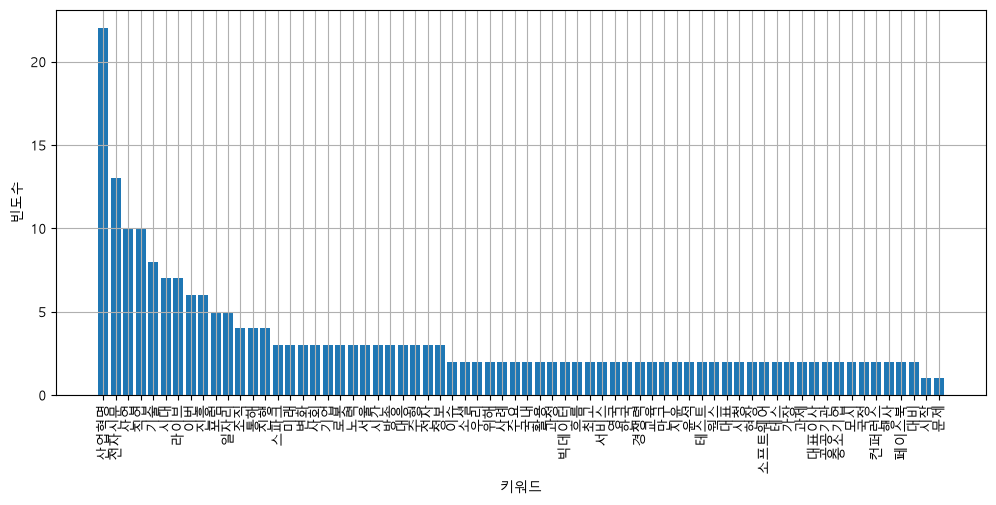

In [10]:
plt.figure(figsize = (12, 5))
plt.xlabel('키워드') # 한글은 폰트 지정 안되면 꺠짐. 위에서 폰트 지정한 이유
plt.ylabel('빈도수')
plt.grid(True)
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)
plt.bar(range(len(word_count)), sorted_Values, align = 'center')
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 'vertical')
plt.show()

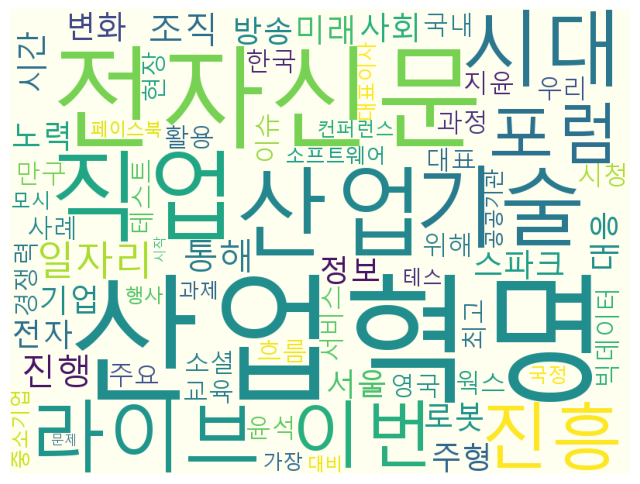

In [21]:
wc = WordCloud(font_path, background_color = 'ivory', width = 800, height = 600)
cloud = wc.generate_from_frequencies(word_count)
plt.figure(figsize = (8,8))
plt.imshow(cloud)
plt.axis('off')
plt.show()

In [22]:
cloud.to_file(inputFileName + '_cloud.jpg')